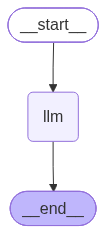

In [9]:

from IPython.core.display import Image
from typing import TypedDict, Annotated

from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
from langchain_core.messages import HumanMessage, AIMessage, BaseMessage
from langgraph.constants import START, END
from langgraph.graph import StateGraph, MessagesState

load_dotenv()

# 1.初始化模型
model = init_chat_model(
    "deepseek-v4-flash",
    extra_body={"thinking": {"type": "disabled"}}
)


# def add(old, new):
#     return old + new

# 2.创建State
# class LLMState(TypedDict):
#     messages: Annotated[list[BaseMessage], add]

# 3.创建Node
def llm_node(state: MessagesState):
    # 调用模型，传入list[Message]，返回 AIMessage
    response = model.invoke(state["messages"])
    return {"messages": [response]}

# 4.添加Edge，连接Node，形成Graph
builder = StateGraph(MessagesState)

builder.add_node("llm", llm_node)

builder.add_edge(START, "llm")
builder.add_edge("llm", END)

graph = builder.compile()

display(Image(graph.get_graph(xray=True).draw_mermaid_png()))


调用model和调用Agent：
- 入参：
    - model, 传入的str或者`list[BaseMessage]`
    - agent, 传入的是dict，dict里有messages，是一个消息列表`list[BaseMessage]`
- 返回值：
    - model，返回的AIMessage
    - agent，返回的是dict，dict里有messages，是一个消息列表`list[BaseMessage]`

In [10]:
# 5.调用Graph
result = graph.invoke(
    {
        "messages": [HumanMessage("你好，你是谁？")]
    }
)
print(result)

{'messages': [HumanMessage(content='你好，你是谁？', additional_kwargs={}, response_metadata={}, id='54e169d3-72f7-4a24-b353-0468ddbc2f63'), AIMessage(content='你好！我是DeepSeek，由深度求索公司创造的AI助手。😊\n\n我是一个纯文本模型，可以帮你解答各种问题、处理文档、进行对话交流。我的一些特点包括：\n\n✨ **完全免费**使用\n📚 **超长上下文**（1M tokens），能一次性处理《三体》三部曲那么大的内容\n📎 **支持文件上传**，可以处理图片、PDF、Word、Excel等文件中的文字信息\n🔍 **支持联网搜索**（需要手动开启）\n🎤 **App端支持语音输入**\n\n我的知识截止到2025年5月，会尽我所能为你提供准确、有用的帮助！\n\n有什么我可以帮你的吗？无论是学习、工作还是生活中的问题，都可以随时问我哦！💪', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 160, 'prompt_tokens': 8, 'total_tokens': 168, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 8}, 'model_provider': 'deepseek', 'model_name': 'deepseek-v4-flash', 'system_fingerprint': 'a26a7955944dc5c60445bff77fac9c8e', 'id': '9cef94d2-fc00-48f2-80b9-1f5d937db611', 'finish_reason': 'stop', 'logprobs': None}

In [12]:
stream = graph.stream_events(
    {
        "messages": [HumanMessage("你好，你是谁？")]
    },
    version="v3"
)
for message in stream.messages:
    for chunk in message.text:
        print(chunk, end="", flush=True)

你好呀！我是DeepSeek，由深度求索公司创造的AI助手。😊

我的使命就是帮你解答问题、提供信息、进行各种有趣的对话！无论你是想聊聊天、寻求建议、解决学习或工作上的难题，还是纯粹想探索一些新奇的想法，我都会全力以赴。

我的一些特点：
- **免费使用**，随时为你服务
- **超强上下文**（1M tokens），可以处理超长文档
- **支持文件上传**，可以读取图片、PDF、Word等文件中的文字信息
- **可以联网搜索**（需要你手动开启）
- **知识更新到2025年5月**

有什么我可以帮你的吗？尽管说，我很乐意为你效劳！💪✨